# Solution 2 (comparison only): seed-anchored similarity + one-shot assignment

> **Throwaway experiment.** The main method is greedy percolation (`solution.ipynb`). This notebook only tests an alternative and compares it with the main results. All its outputs are in `solution2_out/`; delete that folder and this notebook to remove everything. Main deliverables (`config.json`, `results/`, `predictions/`, `report.md`) are only **read**, never written.

**Idea.** Describe every node by *which seeds it is adjacent to*: row `u` of `A[:, seeds_a]` for A and row `v` of `B[:, seeds_b]` for B (column `i` is the same seed in both graphs). Nodes that are the same person should touch the same seeds. Compute a similarity matrix between unseeded nodes, then solve **one** global assignment (`scipy.optimize.linear_sum_assignment`) instead of matching greedily and iterating.

Similarity options: `dot` (number of shared seed neighbours), `cosine`, `jaccard`; optional `idf` weighting that down-weights high-degree seeds; optional rejection threshold `tau` (leave a pair unmatched if its similarity is below it).

**Expected weakness:** a node with no seed neighbour has an all-zero feature vector, so nothing separates it from other such nodes. With few seeds (1%) many nodes look like this. Percolation avoids the problem by turning every new match into a new anchor.

## 1. Setup and data loading (same loader and metrics as the main notebook)

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy.optimize import linear_sum_assignment

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
DATA = Path('student/seed_based')
MAIN = Path('results')            # main (percolation) results: read only
OUT = Path('solution2_out')       # everything this notebook writes
OUT.mkdir(exist_ok=True)
(OUT / 'figs').mkdir(exist_ok=True)

In [2]:
def build_adj(edges, n):
    """Symmetric 0/1 CSR adjacency without self-loops or duplicate edges."""
    m = sp.coo_matrix((np.ones(len(edges)), (edges.source, edges.target)), shape=(n, n))
    m = (m + m.T).tocsr()
    m.setdiag(0)
    m.eliminate_zeros()
    m.data[:] = 1.0
    return m


def load_instance(split, name, seed_kind="random", seed_pct=5):
    d = DATA / split / name
    n_a = len(pd.read_csv(d / "nodes_a.csv"))
    n_b = len(pd.read_csv(d / "nodes_b.csv"))
    A = build_adj(pd.read_csv(d / "edges_a.csv"), n_a)
    B = build_adj(pd.read_csv(d / "edges_b.csv"), n_b)
    seeds = pd.read_csv(d / f"seeds_{seed_kind}_{seed_pct:02d}.csv")
    seeds = dict(zip(seeds.node_a, seeds.node_b))
    gt = d / "ground_truth.csv"
    truth = None
    if gt.exists():
        t = pd.read_csv(gt)
        truth = dict(zip(t.node_a, t.node_b))
    meta = json.loads((d / "metadata.json").read_text())
    return A, B, seeds, truth, meta


In [3]:
def evaluate(pred, truth, seeds, n):
    """Precision / recall / F1 / coverage, overall and on unseeded nodes only."""
    correct = sum(truth.get(a) == b for a, b in pred.items())
    p = correct / len(pred) if pred else 0.0
    r = correct / n
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    un_pred = {a: b for a, b in pred.items() if a not in seeds}
    un_truth_n = n - len(seeds)
    un_correct = sum(truth.get(a) == b for a, b in un_pred.items())
    un_p = un_correct / len(un_pred) if un_pred else 0.0
    un_r = un_correct / un_truth_n if un_truth_n else 0.0
    un_f1 = 2 * un_p * un_r / (un_p + un_r) if un_p + un_r else 0.0
    return dict(
        precision=p, recall=r, f1=f1, coverage=len(pred) / n,
        unseeded_precision=un_p, unseeded_recall=un_r, unseeded_f1=un_f1,
        unseeded_coverage=len(un_pred) / un_truth_n if un_truth_n else 0.0,
    )


def degree_rank_baseline(A, B, seeds):
    """Pair unseeded nodes by degree rank (a deliberately weak floor)."""
    da = np.asarray(A.sum(1)).ravel()
    db = np.asarray(B.sum(1)).ravel()
    ua = [u for u in np.argsort(-da, kind="stable") if u not in seeds]
    used_b = set(seeds.values())
    ub = [v for v in np.argsort(-db, kind="stable") if v not in used_b]
    pred = dict(seeds)
    pred.update(zip(ua, ub))
    return pred


## 2. The method
`match_seed_sim` builds the seed-adjacency features, the similarity matrix over unseeded nodes, solves one rectangular assignment, and optionally rejects low-similarity pairs. A small degree-similarity term (always below any real similarity difference) breaks ties. It also logs each match's similarity and its gap to the best alternative in the row.

In [4]:
def seed_features(A, B, seeds):
    sa, sb = list(seeds.keys()), list(seeds.values())
    Xa = A[:, sa].toarray().astype(np.float32)
    Xb = B[:, sb].toarray().astype(np.float32)
    dA = np.asarray(A.sum(1)).ravel()
    dB = np.asarray(B.sum(1)).ravel()
    return Xa, Xb, dA, dB, sa, sb


def similarity(Xa, Xb, kind="dot", idf_w=None):
    """Similarity of every A-row to every B-row of the seed-adjacency features."""
    if idf_w is not None and kind != "jaccard":
        Xa, Xb = Xa * idf_w, Xb * idf_w
    inter = Xa @ Xb.T
    if kind == "dot":
        return inter
    if kind == "cosine":
        na = np.linalg.norm(Xa, axis=1, keepdims=True)
        nb = np.linalg.norm(Xb, axis=1, keepdims=True)
        return inter / np.maximum(na * nb.T, 1e-9)
    if kind == "jaccard":
        ca = Xa.sum(1, keepdims=True)
        cb = Xb.sum(1, keepdims=True)
        return inter / np.maximum(ca + cb.T - inter, 1e-9)
    raise ValueError(kind)


def match_seed_sim(A, B, seeds, kind="dot", idf=False, tau=None):
    """Seed-anchored similarity + ONE global assignment on the unseeded nodes."""
    n = A.shape[0]
    Xa, Xb, dA, dB, sa, sb = seed_features(A, B, seeds)
    w = (1.0 / np.log(1.0 + (dA[sa] + dB[sb]) / 2.0)).astype(np.float32) if idf else None
    S = similarity(Xa, Xb, kind, w)
    ua = np.array([u for u in range(n) if u not in seeds])
    used_b = set(seeds.values())
    ub = np.array([v for v in range(n) if v not in used_b])
    Su = S[np.ix_(ua, ub)]
    tb = -np.abs(dA[ua][:, None] - dB[ub][None, :]) / (max(dA.max(), dB.max()) + 1) * 1e-3
    ri, ci = linear_sum_assignment(-(Su + tb))
    # gap to the best alternative in the same row (confidence), on raw similarity
    top2 = -np.sort(-Su, axis=1)[:, :2]
    pred, log = dict(seeds), []
    for i, j in zip(ri, ci):
        s = float(Su[i, j])
        alt = float(top2[i, 1]) if s >= top2[i, 0] else float(top2[i, 0])
        if tau is None or s >= tau:
            pred[int(ua[i])] = int(ub[j])
            log.append((int(ua[i]), int(ub[j]), s, s - alt))
    return pred, pd.DataFrame(log, columns=["node_a", "node_b", "score", "gap"])

In [5]:
# Sanity checks on one instance (5% random seeds)
A, B, seeds, truth, meta = load_instance('val', 'erdos_renyi_hard_00', 'random', 5)
n = A.shape[0]
print({k: round(v, 3) for k, v in evaluate(dict(truth), truth, seeds, n).items()})   # perfect -> 1.0
print(round(evaluate(dict(seeds), truth, seeds, n)['unseeded_recall'], 3))            # seeds only -> 0
# 'dot' similarity must equal the votes in percolation's initial score matrix A @ P @ B.T
P = sp.csr_matrix((np.ones(len(seeds)), (list(seeds), list(seeds.values()))), shape=(n, n))
M0 = (A @ P @ B.T).toarray()
Xa, Xb, *_ = seed_features(A, B, seeds)
assert np.allclose(Xa @ Xb.T, M0), "dot similarity != percolation initial votes"
print("dot similarity == percolation initial vote matrix: OK")
pred, info = match_seed_sim(A, B, seeds)
assert len(set(pred)) == len(pred) and len(set(pred.values())) == len(pred), "duplicate ids"
demo = pd.DataFrame({
    'seeds only': evaluate(dict(seeds), truth, seeds, n),
    'degree rank': evaluate(degree_rank_baseline(A, B, seeds), truth, seeds, n),
    'seed-sim (dot)': evaluate(pred, truth, seeds, n),
}).T[['precision', 'recall', 'f1', 'coverage', 'unseeded_precision', 'unseeded_recall']]
display(demo.round(3))

{'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'coverage': 1.0, 'unseeded_precision': 1.0, 'unseeded_recall': 1.0, 'unseeded_f1': 1.0, 'unseeded_coverage': 1.0}
0.0
dot similarity == percolation initial vote matrix: OK


,precision,recall,f1,coverage,unseeded_precision,unseeded_recall
seeds only,1.000,0.050,0.095,0.05,0.000,0.000
degree rank,0.052,0.052,0.052,1.00,0.002,0.002
seed-sim (dot),0.569,0.569,0.569,1.00,0.546,0.546


## 3. Tuning on Train only
Same protocol as the main notebook: grid scored by mean unseeded F1 over Train instances at 1% and 5% seeds (random and degree). `tau` values depend on the similarity scale.

In [6]:
def list_instances(split):
    return sorted(p.name for p in (DATA / split).iterdir() if p.is_dir())


def run_one(split, name, kind, pct, cfg):
    A, B, seeds, truth, meta = load_instance(split, name, kind, pct)
    t = time.perf_counter()
    pred, _ = match_seed_sim(A, B, seeds, **cfg)
    dt = time.perf_counter() - t
    row = evaluate(pred, truth, seeds, A.shape[0])
    row.update(split=split, instance=name, family=meta["family"], difficulty=meta["difficulty"], n=A.shape[0],
               seed_kind=kind, seed_pct=pct, runtime=dt, method="seed_sim", cfg=json.dumps(cfg, sort_keys=True))
    return row


def run_grid(split, settings, cfgs):
    jobs = [(split, nm, k, p, c) for nm in list_instances(split) for (k, p) in settings for c in cfgs]
    return pd.DataFrame(Parallel(n_jobs=-1)(delayed(run_one)(*j) for j in jobs))


TAUS = {"dot": (None, 1, 2), "cosine": (None, 0.1, 0.3), "jaccard": (None, 0.05, 0.15)}
grid = [dict(kind=k, idf=i, tau=t) for k in TAUS for i in (False, True) for t in TAUS[k]]
TUNE_SETTINGS = [("random", 1), ("degree", 1), ("random", 5), ("degree", 5)]
tune = run_grid("train", TUNE_SETTINGS, grid)
s = (tune.groupby("cfg")[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "runtime"]].mean()
     .sort_values("unseeded_f1", ascending=False))
display(s.round(3))
best_cfg = json.loads(s.index[0]); print("best Train config:", best_cfg)

,unseeded_precision,unseeded_recall,unseeded_f1,coverage,runtime
cfg,,,,,
"{""idf"": false, ""kind"": ""dot"", ""tau"": 1}",0.406,0.262,0.301,0.557,0.020
"{""idf"": true, ""kind"": ""jaccard"", ""tau"": 0.15}",0.397,0.255,0.292,0.558,0.017
"{""idf"": false, ""kind"": ""jaccard"", ""tau"": 0.15}",0.397,0.255,0.292,0.558,0.017
"{""idf"": true, ""kind"": ""jaccard"", ""tau"": 0.05}",0.397,0.255,0.292,0.558,0.017
"{""idf"": false, ""kind"": ""jaccard"", ""tau"": 0.05}",0.397,0.255,0.292,0.558,0.017
"{""idf"": false, ""kind"": ""cosine"", ""tau"": 0.3}",0.386,0.251,0.287,0.559,0.018
"{""idf"": false, ""kind"": ""cosine"", ""tau"": 0.1}",0.386,0.251,0.287,0.559,0.017
"{""idf"": true, ""kind"": ""cosine"", ""tau"": 0.3}",0.382,0.249,0.285,0.559,0.018
"{""idf"": true, ""kind"": ""cosine"", ""tau"": 0.1}",0.382,0.249,0.285,0.559,0.018


best Train config: {'idf': False, 'kind': 'dot', 'tau': 1}


In [7]:
# Confirm once on Val (best config vs plain dot) and freeze
val_cmp = run_grid("val", TUNE_SETTINGS, [dict(kind="dot", idf=False, tau=None), best_cfg])
display(val_cmp.groupby(["cfg", "seed_kind", "seed_pct"])[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage"]].mean().round(3))
key = json.dumps(best_cfg, sort_keys=True)
print(f"mean unseeded F1 of chosen config: Train {tune[tune.cfg == key].unseeded_f1.mean():.3f} | Val {val_cmp[val_cmp.cfg == key].unseeded_f1.mean():.3f}")
(OUT / "config2.json").write_text(json.dumps(dict(method="seed similarity + one-shot assignment", params=best_cfg), indent=2))
print((OUT / "config2.json").read_text())

unseeded_precision  unseeded_recall  unseeded_f1  coverage
cfg                                        seed_kind seed_pct                                                            
{"idf": false, "kind": "dot", "tau": 1}    degree    1                      0.181            0.073        0.102     0.432
                                                     5                      0.654            0.562        0.603     0.864
                                           random    1                      0.220            0.045        0.072     0.259
                                                     5                      0.540            0.367        0.427     0.680
{"idf": false, "kind": "dot", "tau": null} degree    1                      0.085            0.085        0.085     1.000
                                                     5                      0.571            0.571        0.571     1.000
                                           random    1                      0.059            0.059        0.059     1.000
                                                     5                      0.377            0.377        0.377     1.000

mean unseeded F1 of chosen config: Train 0.301 | Val 0.301
{
  "method": "seed similarity + one-shot assignment",
  "params": {
    "idf": false,
    "kind": "dot",
    "tau": 1
  }
}


## 4. Full experiments (frozen config), Train + Val, all seed strategies and levels

In [8]:
ALL_SETTINGS = [(k, p) for k in ("random", "degree") for p in (1, 5, 10)]
cfg2 = json.loads((OUT / "config2.json").read_text())["params"]
s2 = pd.concat([run_grid(sp_, ALL_SETTINGS, [cfg2]) for sp_ in ("train", "val")], ignore_index=True)
for sp_ in ("train", "val"):
    s2[s2.split == sp_].to_csv(OUT / f"{sp_}_results.csv", index=False)
print(len(s2), "runs saved to", OUT)
metrics = ["precision", "recall", "f1", "coverage", "unseeded_precision", "unseeded_recall", "unseeded_f1"]
display(s2.groupby(["split", "seed_kind", "seed_pct"])[metrics].mean().round(3))

216 runs saved to solution2_out


precision  recall     f1  coverage  unseeded_precision  unseeded_recall  unseeded_f1
split seed_kind seed_pct                                                                                      
train degree    1             0.201   0.083  0.116     0.427               0.180            0.074        0.103
                5             0.676   0.589  0.628     0.870               0.656            0.568        0.607
                10            0.923   0.891  0.907     0.964               0.914            0.879        0.896
      random    1             0.293   0.054  0.086     0.248               0.254            0.044        0.071
                5             0.573   0.396  0.457     0.681               0.534            0.364        0.421
                10            0.825   0.715  0.761     0.847               0.797            0.683        0.730
val   degree    1             0.201   0.082  0.115     0.432               0.181            0.073        0.102
                5             0.675   0.584  0.624     0.864               0.654            0.562        0.603
                10            0.925   0.892  0.908     0.963               0.916            0.880        0.897
      random    1             0.257   0.055  0.087     0.259               0.220            0.045        0.072
                5             0.578   0.399  0.462     0.680               0.540            0.367        0.427
                10            0.816   0.707  0.753     0.844               0.787            0.674        0.720

## 5. Comparison with the main method (greedy percolation)
Main results are read from `results/{train,val}_results.csv` (written by `solution.ipynb`, never modified here). Rows are matched on split, instance, seed strategy and seed level.

In [9]:
main = pd.concat([pd.read_csv(MAIN / f"{x}_results.csv") for x in ("train", "val")], ignore_index=True)
main = main[main.method == "perc"]
keys = ["split", "instance", "family", "difficulty", "n", "seed_kind", "seed_pct"]
cols = ["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "runtime"]
cmp = main[keys + cols].merge(s2[keys + cols], on=keys, suffixes=("_perc", "_sim"))
assert len(cmp) == len(s2) == len(main), (len(cmp), len(s2), len(main))
cmp["recall_diff"] = cmp.unseeded_recall_sim - cmp.unseeded_recall_perc

display(Markdown("**Unseeded recall by seed setting (Train+Val, mean over instances)**"))
t1 = cmp.groupby(["seed_kind", "seed_pct"])[["unseeded_recall_perc", "unseeded_recall_sim", "unseeded_precision_perc",
                                              "unseeded_precision_sim", "coverage_perc", "coverage_sim"]].mean().round(3)
display(t1)
display(Markdown("**Unseeded recall by family and seed level (random seeds)**"))
display(cmp[cmp.seed_kind == "random"].pivot_table(index="family", columns="seed_pct",
        values=["unseeded_recall_perc", "unseeded_recall_sim"]).round(3))
display(Markdown("**Unseeded recall by difficulty at 5% seeds**"))
display(cmp[cmp.seed_pct == 5].pivot_table(index="difficulty", columns="seed_kind",
        values=["unseeded_recall_perc", "unseeded_recall_sim"]).round(3))
display(Markdown("**Runtime per instance by size (seconds)**"))
display(cmp.groupby("n")[["runtime_perc", "runtime_sim"]].mean().round(3))
display(Markdown("**Instances where seed-sim is within 0.01 unseeded recall of percolation, by seed level**"))
display(cmp.assign(close=cmp.recall_diff.abs() <= 0.01).groupby("seed_pct").close.mean().round(2))

**Unseeded recall by seed setting (Train+Val, mean over instances)**

unseeded_recall_perc  unseeded_recall_sim  unseeded_precision_perc  unseeded_precision_sim  coverage_perc  coverage_sim
seed_kind seed_pct                                                                                                                         
degree    1                        0.979                0.073                    0.979                   0.180          1.000         0.428
          5                        1.000                0.566                    1.000                   0.656          1.000         0.869
          10                       1.000                0.879                    1.000                   0.915          1.000         0.964
random    1                        0.913                0.044                    0.913                   0.246          0.999         0.251
          5                        1.000                0.365                    1.000                   0.536          1.000         0.681
          10                       1.000                0.681                    1.000                   0.795          1.000         0.846

**Unseeded recall by family and seed level (random seeds)**

unseeded_recall_perc           unseeded_recall_sim              
seed_pct                                  1    5    10                  1      5      10
family                                                                                  
erdos_renyi                            0.993  1.0  1.0               0.051  0.466  0.836
preferential_attachment                0.837  1.0  1.0               0.040  0.188  0.376
stochastic_block                       0.909  1.0  1.0               0.043  0.440  0.831

**Unseeded recall by difficulty at 5% seeds**

unseeded_recall_perc        unseeded_recall_sim       
seed_kind                degree random              degree random
difficulty                                                       
easy                      0.999    1.0               0.509  0.297
hard                      1.000    1.0               0.609  0.426
medium                    1.000    1.0               0.581  0.371

**Runtime per instance by size (seconds)**

,runtime_perc,runtime_sim
n,,
300,0.023,0.002
600,0.137,0.009
1000,0.566,0.034


**Instances where seed-sim is within 0.01 unseeded recall of percolation, by seed level**

seed_pct
1     0.01
5     0.00
10    0.01
Name: close, dtype: float64

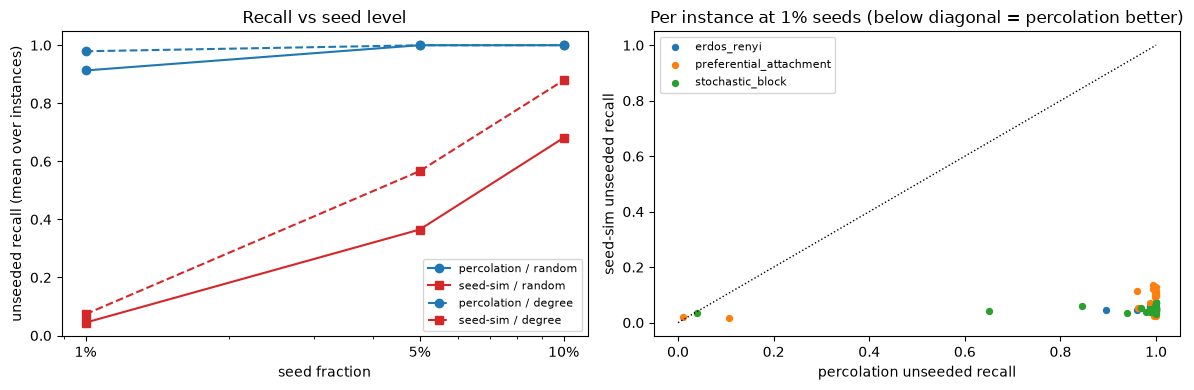

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for kind, ls in (("random", "-"), ("degree", "--")):
    g = cmp[cmp.seed_kind == kind].groupby("seed_pct")
    ax[0].plot(g.unseeded_recall_perc.mean().index, g.unseeded_recall_perc.mean().values, ls, marker="o", c="C0", label=f"percolation / {kind}")
    ax[0].plot(g.unseeded_recall_sim.mean().index, g.unseeded_recall_sim.mean().values, ls, marker="s", c="C3", label=f"seed-sim / {kind}")
ax[0].set_xscale("log"); ax[0].set_xticks([1, 5, 10]); ax[0].set_xticklabels(["1%", "5%", "10%"])
ax[0].set_xlabel("seed fraction"); ax[0].set_ylabel("unseeded recall (mean over instances)"); ax[0].legend(fontsize=8); ax[0].set_title("Recall vs seed level")
for fam, g in cmp[cmp.seed_pct == 1].groupby("family"):
    ax[1].scatter(g.unseeded_recall_perc, g.unseeded_recall_sim, label=fam, s=18)
ax[1].plot([0, 1], [0, 1], "k:", lw=1); ax[1].set_xlabel("percolation unseeded recall"); ax[1].set_ylabel("seed-sim unseeded recall")
ax[1].set_title("Per instance at 1% seeds (below diagonal = percolation better)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figs" / "comparison.png", dpi=130); plt.show()

## 6. Precision vs coverage with a rejection threshold
One-shot assignment always assigns every node; thresholding the similarity (or the gap to the runner-up) trades coverage for precision. Post-hoc analysis on Val, 5% and 1% random seeds, using the logged similarities of the frozen config.

In [11]:
rows = []
for pct in (1, 5):
    for name in list_instances("val"):
        A_, B_, s_, tr_, mt_ = load_instance("val", name, "random", pct)
        _, inf_ = match_seed_sim(A_, B_, s_, **dict(cfg2, tau=None))
        inf_["correct"] = [tr_[a] == b for a, b in zip(inf_.node_a, inf_.node_b)]
        inf_["pct"] = pct; inf_["n_unseeded"] = A_.shape[0] - len(s_)
        rows.append(inf_)
cf = pd.concat(rows, ignore_index=True)
q = []
for pct, g in cf.groupby("pct"):
    for thr in (0, 1, 2, 3):
        k = g[g.gap >= thr] if thr else g
        q.append(dict(seeds=f"random {pct}%", min_gap=thr, kept=len(k) / len(g), precision_of_kept=k.correct.mean()))
display(pd.DataFrame(q).set_index(["seeds", "min_gap"]).round(3))

kept  precision_of_kept
seeds     min_gap                          
random 1% 0        1.000              0.053
          1        0.006              0.806
          2        0.000                NaN
          3        0.000                NaN
random 5% 0        1.000              0.394
          1        0.173              0.972
          2        0.042              1.000
          3        0.007              1.000

## Takeaways (seed-sim vs percolation)

**Percolation is far better in every setting.** Mean unseeded recall over Train+Val: at 5% seeds, percolation 1.000 vs seed-sim 0.57 (degree seeds) / 0.37 (random seeds); at 10% seeds 1.000 vs 0.88 / 0.68; at 1% seeds 0.98 / 0.91 vs 0.07 / 0.04. Seed-sim is within 0.01 recall of percolation on essentially no instance.

**Why.** A one-shot method can only use direct adjacency to the *given* seeds. Nodes that touch no seed (or touch the same one or two seeds as many others) cannot be told apart, and the assignment among them is close to arbitrary. At 5% seeds in these graphs, a large fraction of nodes still has too few seed neighbours. Percolation turns each confident match into a new anchor, so evidence snowballs; seed-sim never gets more evidence than the first round.

**Seed strategy matters much more for seed-sim.** Degree seeds touch many nodes, so recall at 5% is 0.57 vs 0.37 for random seeds. For percolation the two are nearly identical at 5%+. Preferential-attachment graphs are hardest for seed-sim (0.19 recall at 5% random seeds): most nodes are low-degree and touch no seed.

**Difficulty (edge noise) is secondary:** the by-difficulty differences are small compared with the effect of seed level and seed type.

**Rejection threshold.** Always assigning everything gives low precision (0.39 at 5% random seeds). Keeping only pairs whose similarity beats the runner-up by 1 vote gives 0.97 precision but keeps only 17% of nodes. So seed-sim can be a high-precision partial matcher, but not a high-coverage one. The tuning picked `dot` with `tau=1` (keep pairs sharing at least one seed neighbour) because that maximises F1 by trading coverage (0.56 on Train) for precision; the similarity measures (dot, cosine, Jaccard) differ little.

**Caveat on the grid:** with `idf=True` the weights are below 1, so my `tau` values of 1 and 2 for `dot` reject almost everything; those rows in the tuning table reflect a threshold-scale mismatch, not a fair test of IDF weighting. IDF made no difference without a threshold.

**Runtime.** Seed-sim is about 15x faster (0.03 s vs 0.57 s at n=1000), but speed is not the bottleneck here.

**Conclusion.** Keep percolation as the main method. Seed-sim is a useful simple baseline, and its round-one vote matrix is exactly percolation's initial score matrix (checked in the notebook).